# Un primer TestResult sobre una porción real de 50 tarjetas

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el cuaderno 01 de este tema (instalar y abrir un artefacto)
- **Tiempo de lectura:** unos 25 minutos

## Objetivos

Al terminar este cuaderno puedes:

- llamar a una prueba del motor sobre tus propios arreglos y leer el `TestResult` que devuelve, campo por campo;
- decir qué miden el AUC, la prueba de Jeffreys y el puntaje de Brier, y reproducir las dos primeras con una verificación independiente;
- explicar por qué la misma prueba da un intervalo ancho con 50 tarjetas y uno angosto con 9.000, y por qué una luz verde con 50 tarjetas es una evidencia débil;
- comparar un recálculo con la fila versionada, nombrando la versión del motor que la calculó.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import dataclasses
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son una porción del caso C01 (PD de tarjetas de crédito minoristas) tal como Contraste la versiona. Las 30.000 tarjetas vienen del archivo de tarjetas de crédito de Taiwán de UCI (Yeh, 2009; CC BY 4.0, clase de licencia `mirror-allowed`, https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). El pipeline ajustó una scorecard WoE (peldaño P1) sobre una porción de entrenamiento y puntuó un holdout bloqueado de 9.000 tarjetas. El artefacto holdout guarda una **muestra de 50 tarjetas** con su resultado (`targets`, 1 si cayó en incumplimiento en el horizonte) y la PD que les dio la scorecard (`scorecard_pd`).

- **Archivo que se lee:** `data/derived/C01/holdout.json`, la clave `outputs.sample` para las 50 tarjetas y las filas de pruebas versionadas en `tests` para las 9.000.
- **Por qué 50:** lo bastante pequeña para mirar cada tarjeta, lo bastante grande para correr las pruebas. Es además una advertencia deliberada: validar con una muestra pequeña es la situación en que están muchos validadores.

La celda siguiente carga el artefacto y las 50 tarjetas, e imprime lo que contienen.

In [2]:
# Cargar el artefacto holdout y la muestra de 50 tarjetas (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
holdout = json.loads((ROOT / "data" / "derived" / "C01" / "holdout.json").read_text(encoding="utf-8"))

sample = holdout["outputs"]["sample"]
ids = sample["ids"]
y = np.array(sample["targets"])
pd_hat = np.array(sample["scorecard_pd"])

print("tarjetas en la muestra:", len(ids), "| incumplimientos:", int(y.sum()), "| tasa de incumplimiento:", round(float(y.mean()), 4))
print("PD media de la scorecard:", round(float(pd_hat.mean()), 4), "| incumplimientos esperados:", round(float(pd_hat.sum()), 2))
print("tarjetas del holdout:", holdout["outputs"]["n"], "| incumplimientos del holdout:", holdout["outputs"]["defaults"])
for k in range(3):
    print(ids[k], "incumplimiento:", int(y[k]), "| PD:", round(float(pd_hat[k]), 4))

tarjetas en la muestra: 50 | incumplimientos: 15 | tasa de incumplimiento: 0.3
PD media de la scorecard: 0.2534 | incumplimientos esperados: 12.67
tarjetas del holdout: 9000 | incumplimientos del holdout: 1991
TW00002 incumplimiento: 1 | PD: 0.2379
TW00004 incumplimiento: 0 | PD: 0.1489
TW00012 incumplimiento: 0 | PD: 0.0952


## Método

Cada prueba del motor es una función que recibe tus arreglos y una política opcional, y devuelve un `TestResult`: el registro de una prueba sobre un modelo y una muestra. Llamamos a tres pruebas. Primero creamos la política que leerán, la que trae el motor por defecto.

In [3]:
# La política por defecto del paquete; es el objeto que convertirá los valores p en luces
policy = rv.default_policy()
print("política:", policy.label)
print("pruebas con umbral:", len(policy.thresholds))

política: riskvalidation-default 2026.10.1
pruebas con umbral: 43


### Paso 1: el AUC, una medida de ordenamiento

El área bajo la curva ROC es la probabilidad de que a un incumplidor elegido al azar se le haya dado una PD mayor que a un no incumplidor elegido al azar, contando los empates como un medio (Hanley y McNeil, 1982):

$$\mathrm{AUC} = P(\hat p_{\text{incumplidor}} > \hat p_{\text{no incumplidor}}) + \tfrac12\, P(\hat p_{\text{incumplidor}} = \hat p_{\text{no incumplidor}})$$

Un AUC de 0,5 ordena igual que el azar y 1 ordena de forma perfecta. `disc_auc`, del motor, lo devuelve con su error estándar y un intervalo de 95% (la fórmula de varianza del BCE, ECB 2019, Anexo 1, sección 3.1). La celda siguiente hace la llamada y lee el resultado.

In [4]:
# Una llamada, un TestResult: el AUC de la scorecard sobre las 50 tarjetas
from riskvalidation.validation import disc_auc

auc = disc_auc(pd_hat, y, policy=policy, model_id="P1-scorecard")
print("test_id:", auc.test_id)
print("AUC:", round(auc.metric, 6), "| gini:", round(auc.extras["gini"], 6))
print("error estándar:", round(auc.extras["se"], 6))
print("intervalo de 95%:", round(auc.extras["ci95_low"], 4), "a", round(auc.extras["ci95_high"], 4))
print("luz:", auc.light.value)
print("nota:", auc.notes)

test_id: disc.auc
AUC: 0.775238 | gini: 0.550476
error estándar: 0.065765
intervalo de 95%: 0.6463 a 0.9041
luz: not_evaluated
nota: policy riskvalidation-default 2026.10.1 holds no thresholds for this test; no light assigned


La definición permite una verificación: comparar cada incumplidor con cada no incumplidor y contar con qué frecuencia el incumplidor recibió la PD más alta. Es una verificación de la definición sobre 50 tarjetas, no una segunda implementación de la prueba; el método sigue siendo el del motor.

In [5]:
# Verificar la definición contando los pares de un incumplidor y un no incumplidor
defaulters = pd_hat[y == 1]
others = pd_hat[y == 0]
pairs = int(len(defaulters) * len(others))
concordant = (defaulters[:, None] > others[None, :]).mean()
ties = (defaulters[:, None] == others[None, :]).mean()

print("pares comparados:", pairs)
print("AUC desde los pares:", round(float(concordant + 0.5 * ties), 6))
print("igual al motor:", bool(np.isclose(concordant + 0.5 * ties, auc.metric)))

pares comparados: 525
AUC desde los pares: 0.775238
igual al motor: True


### Paso 2: la prueba de Jeffreys, una prueba del nivel

El AUC no dice nada sobre si las PD tienen el tamaño correcto. La prueba de Jeffreys lo pregunta para toda una cartera. Su hipótesis nula es que la PD aplicada es mayor o igual que la PD verdadera; rechaza cuando los incumplimientos observados son demasiados para eso. Con $D$ incumplimientos entre $N$ deudores y una PD aplicada, el valor p unilateral es la función de distribución Beta con una a priori de Jeffreys (Brown, Cai y DasGupta, 2001; ECB 2019, sección 2.5.3.1):

$$p = F_{\mathrm{Beta}(D + 1/2,\; N - D + 1/2)}(\mathrm{PD})$$

Un p pequeño significa más incumplimientos de los que admite la PD: el modelo subestima el riesgo. La celda siguiente llama a `pd_jeffreys` con el número de tarjetas, el de incumplimientos y la PD media, e imprime cada campo del `TestResult`.

In [6]:
# Llamar a la prueba de Jeffreys sobre la cartera de 50 tarjetas e imprimir cada campo del resultado
from riskvalidation.validation import pd_jeffreys

n_cards, n_defaults, mean_pd = len(y), int(y.sum()), float(pd_hat.mean())
jeffreys = pd_jeffreys(n=n_cards, d=n_defaults, pd=mean_pd, policy=policy, model_id="P1-scorecard", segment="portfolio")
for field in dataclasses.fields(jeffreys):
    value = getattr(jeffreys, field.name)
    if field.name in ("h0", "reference", "inputs_hash"):
        value = str(value)[:70] + "..."
    print(f"{field.name:14s} {value}")

test_id        pd.jeffreys
h0             the PD applied at the start of the period is greater than or equal to ...
reference      ECB (2019), Instructions for reporting the validation results of inter...
policy_version riskvalidation-default 2026.10.1
light          Light.GREEN
statistic      0.3
p_value        0.22107631615199014
metric         None
alternative    the true PD exceeds the PD applied (underestimation)
alpha_amber    0.05
alpha_red      0.01
n              50
n_events       15
model_id       P1-scorecard
segment        portfolio
inputs_hash    4f49ee00f88bc072ac80a946b765f9bbdb951ef86de747524f1db70505660607...
notes          
extras         {'pd_applied': 0.25341795330732486, 'default_rate': 0.3, 'posterior_q025': 0.1868771325356566, 'posterior_q975': 0.4355279077018387}


El mismo valor p desde una implementación independiente: la función de distribución Beta de SciPy, en la versión fijada. Que coincida hasta los últimos dígitos muestra que el número del motor es la fórmula anterior y nada más.

In [7]:
# Reproducir el valor p con la función de distribución Beta de SciPy
p_scipy = stats.beta.cdf(mean_pd, n_defaults + 0.5, n_cards - n_defaults + 0.5)
print("valor p, SciPy:", round(float(p_scipy), 10))
print("valor p, motor:", round(jeffreys.p_value, 10))
print("igual:", bool(np.isclose(p_scipy, jeffreys.p_value)))
print("incumplimientos esperados a la PD media:", round(n_cards * mean_pd, 2), "| observados:", n_defaults)

valor p, SciPy: 0.2210763162
valor p, motor: 0.2210763162
igual: True
incumplimientos esperados a la PD media: 12.67 | observados: 15


### Paso 3: el puntaje de Brier, una medida del pronóstico

El puntaje de Brier es el error cuadrático medio de la PD como pronóstico del resultado 0/1 (Brier, 1950; Murphy, 1973): menor es mejor, y el motor lo descompone en una parte de confiabilidad (cuánto se alejan las PD de las tasas observadas), una de resolución (cuánto separan) y la incertidumbre del resultado mismo. Las tres partes suman el puntaje solo cuando las PD son constantes dentro de cada tramo, caso en que la descomposición es exacta; con PD continuas no suman, y el motor registra si fue exacta en `extras["decomposition_exact"]`, que imprime la celda siguiente. Es descriptivo: no tiene hipótesis nula y la política por defecto no tiene umbral para él.

In [8]:
# Llamar al puntaje de Brier sobre las 50 tarjetas y leer su descomposición
from riskvalidation.validation import pd_brier

brier = pd_brier(y, pd_hat, policy=policy, model_id="P1-scorecard", segment="portfolio")
print("Puntaje de Brier:", round(brier.metric, 6))
for key in ("reliability", "resolution", "uncertainty", "brier_skill"):
    print(f"{key:12s} {round(brier.extras[key], 6)}")
print("descomposición exacta:", brier.extras["decomposition_exact"])
print("luz:", brier.light.value)

Puntaje de Brier: 0.189701
reliability  0.031935
resolution   0.058
uncertainty  0.21
brier_skill  0.09666
descomposición exacta: False
luz: not_evaluated


### Paso 4: las mismas pruebas sobre las 9.000 tarjetas versionadas

El artefacto holdout versiona estas tres pruebas para todo el holdout de 9.000 tarjetas. La celda siguiente pone el resultado de las 50 tarjetas junto a la fila versionada, con la versión del motor que calculó el artefacto al lado de la instalada, como prescribe el cuaderno 01.

In [9]:
# Poner los resultados de las 50 tarjetas junto a las filas versionadas del holdout de 9.000 tarjetas
committed = {
    row["test_id"]: row
    for row in holdout["tests"]
    if row["model_id"] == "P1-scorecard" and row["segment"] == "portfolio"
}
print("calculado por riskvalidation", holdout["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

auc_all = committed["disc.auc"]
jef_all = committed["pd.jeffreys"]
brier_all = committed["pd.brier"]
print(f"{'':22s} {'50 tarjetas':>12s} {'9000 tarjetas':>12s}")
print(f"{'AUC':22s} {auc.metric:12.4f} {auc_all['metric']:12.4f}")
print(f"{'Ancho del intervalo AUC':22s} {auc.extras['ci95_high'] - auc.extras['ci95_low']:12.4f} {auc_all['extras']['ci95_high'] - auc_all['extras']['ci95_low']:12.4f}")
print(f"{'Valor p de Jeffreys':22s} {jeffreys.p_value:12.4f} {jef_all['p_value']:12.4f}")
print(f"{'Luz de Jeffreys':22s} {jeffreys.light.value:>12s} {jef_all['light']:>12s}")
print(f"{'Puntaje de Brier':22s} {brier.metric:12.4f} {brier_all['metric']:12.4f}")

calculado por riskvalidation 0.4.3 | instalado 0.8.0
                        50 tarjetas 9000 tarjetas
AUC                          0.7752       0.7587
Ancho del intervalo AUC       0.2578       0.0253
Valor p de Jeffreys          0.2211       0.3095
Luz de Jeffreys               green        green
Puntaje de Brier             0.1897       0.1393


La última celda dibuja las dos lecciones. A la izquierda, la PD que la scorecard dio a las 50 tarjetas según el resultado: los incumplidores tienden a estar más arriba, que es el ordenamiento que mide el AUC. A la derecha, el AUC con su intervalo de 95% con 50 y con 9.000 tarjetas: las estimaciones puntuales son cercanas, la incertidumbre no.

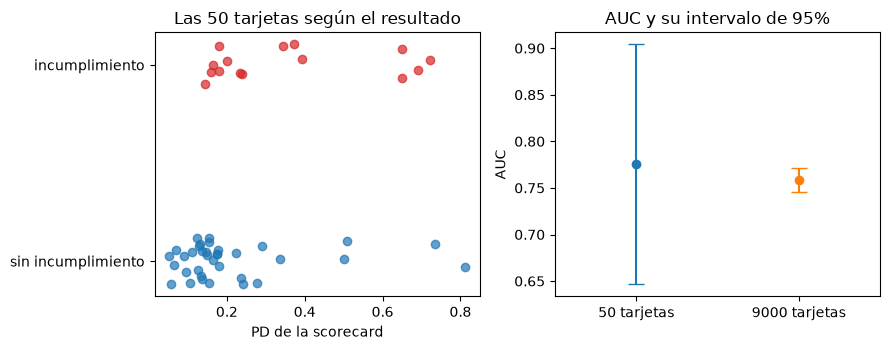

In [10]:
# Dibujar la PD según el resultado y el AUC con su intervalo en los dos tamaños de muestra
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.6))

rng = np.random.default_rng(0)
for outcome, color in ((0, "tab:blue"), (1, "tab:red")):
    values = pd_hat[y == outcome]
    left.scatter(values, outcome + rng.uniform(-0.12, 0.12, len(values)), color=color, alpha=0.7)
left.set_yticks([0, 1])
left.set_yticklabels(["sin incumplimiento", "incumplimiento"])
left.set_xlabel("PD de la scorecard")
left.set_title("Las 50 tarjetas según el resultado")

for position, (label, row) in enumerate((("50", auc.extras | {"metric": auc.metric}), ("9000", auc_all["extras"] | {"metric": auc_all["metric"]}))):
    right.errorbar(position, row["metric"], yerr=[[row["metric"] - row["ci95_low"]], [row["ci95_high"] - row["metric"]]], fmt="o", capsize=6)
right.set_xticks([0, 1])
right.set_xticklabels(["50 tarjetas", "9000 tarjetas"])
right.set_ylabel("AUC")
right.set_title("AUC y su intervalo de 95%")
right.set_xlim(-0.5, 1.5)
fig.tight_layout()
plt.show()

## Resultados

- **Ordenamiento.** La scorecard ordena bien las 50 tarjetas: el AUC es 0,775 según el motor y según el conteo de pares, y el AUC versionado con 9.000 tarjetas es 0,759. El intervalo con 50 tarjetas, de 0,65 a 0,90 aproximadamente, contiene el valor versionado; el intervalo con 9.000 tarjetas va de 0,75 a 0,77 aproximadamente. El ordenamiento es real y la estimación con 50 tarjetas es imprecisa.
- **Nivel.** El valor p de Jeffreys es 0,22 con 50 tarjetas y 0,31 con 9.000, ambos verdes bajo la política por defecto. Con 50 tarjetas la luz verde es una evidencia débil: con solo 15 incumplimientos la prueba tiene poca potencia para rechazar una PD moderadamente baja. Una luz verde es la ausencia de evidencia en contra del modelo, no la prueba de que las PD sean correctas.
- **Pronóstico.** El puntaje de Brier es 0,190 con 50 tarjetas y 0,139 con 9.000. No tiene luz: mide, y un validador lo lee frente al puntaje de Brier de un modelo que predice la tasa base (el término `uncertainty`). Las partes impresas arriba no suman aquí el puntaje (0,032 menos 0,058 más 0,210 es 0,184, frente a 0,190): la descomposición no es exacta con estas PD continuas, así que lee las tres partes como indicadores, no como una identidad.
- **Lo que da un `TestResult`** y un número suelto no da: la hipótesis nula, el sentido de la alternativa, la política que lo coloreó, los tamaños de muestra, un hash de los insumos y la fuente que define la prueba. Eso hace auditable una fila de un informe de validación.

Lo que este cuaderno no muestra: cómo produjo la política los colores (cuaderno 03), qué pasa cuando se corren muchas pruebas sobre una muestra (cuaderno 04) ni cómo se construyó la scorecard (tema 02).

## Resumen

- Una llamada devuelve un `TestResult`: el estadístico o la métrica, el valor p, la hipótesis nula, la etiqueta de la política y la luz, los tamaños de muestra, un hash de los insumos y la referencia.
- El AUC mide el ordenamiento, la prueba de Jeffreys mide el nivel de las PD, el puntaje de Brier mide el pronóstico. Un modelo puede ordenar bien y aun así tener mal el tamaño, por eso un validador corre todas.
- La misma prueba con 50 y con 9.000 tarjetas da estimaciones puntuales cercanas e incertidumbre muy distinta; lee el intervalo antes que el color.
- Un recálculo se compara con la fila versionada solo después de nombrar la versión del motor que la calculó.

**Qué probar a continuación.** Cambia la porción: toma las primeras 25 tarjetas y luego las 50, y mira cómo se mueven el intervalo del AUC y el valor p de Jeffreys. Después lee `docs/guides/03_read-a-validation-report.md` y sigue con el cuaderno 03.

## Referencias

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Anexo 1 (sección 3.1) y sección 2.5.3.1. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Hanley, J. A. y McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Brier, G. W. (1950), Monthly Weather Review 78(1), doi 10.1175/1520-0493(1950)078<0001:VOFEIT>2.0.CO;2, y Murphy, A. H. (1973), Journal of Applied Meteorology 12(4), como los cita la entrada `pd.brier` del motor.
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients